### Implementing simple Chatbot Using LangGraph

In [2]:
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END

## Reducers
from typing import Annotated
from langgraph.graph.message import add_messages

In [3]:
class State(TypedDict):
    messages:Annotated[list,add_messages]

In [5]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")


In [6]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

llm.invoke("Hello")

AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "Hello". We need to respond appropriately. It\'s a simple greeting. We can respond with a friendly greeting.'}, response_metadata={'token_usage': {'completion_tokens': 44, 'prompt_tokens': 72, 'total_tokens': 116, 'completion_time': 0.091403146, 'completion_tokens_details': {'reasoning_tokens': 26}, 'prompt_time': 0.01102317, 'prompt_tokens_details': None, 'queue_time': 0.22126743, 'total_time': 0.102426316}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_5a93aea882', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1780a-fe8d-7772-b070-bf6658db8d9a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 44, 'total_tokens': 116, 'output_token_details': {'reasoning': 26}})

### We Will start With Creating Nodes

In [12]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

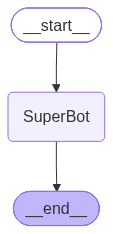

In [13]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [19]:
## Invocation

config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Hi,My name is Aadi And I like cricket"},config)

{'messages': [HumanMessage(content='Hi, my name is Krish and I like cricket', additional_kwargs={}, response_metadata={}, id='63a1ce80-928d-4a7c-b845-7520ab3f632a'),
  AIMessage(content='Hi Krish! Nice to meet you. 😊  \nCricket’s such a fun sport—do you have a favorite team or player? Or maybe a memorable match you’ve enjoyed watching? Let me know!', additional_kwargs={'reasoning_content': 'The user says "Hi, my name is Krish and I like cricket". Likely they are greeting. We should respond politely, maybe ask about cricket preferences. No disallowed content. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 94, 'prompt_tokens': 82, 'total_tokens': 176, 'completion_time': 0.198479801, 'completion_tokens_details': {'reasoning_tokens': 43}, 'prompt_time': 0.003526539, 'prompt_tokens_details': None, 'queue_time': 0.397755533, 'total_time': 0.20200634}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_803c0ba83d', 'service_tier': 'on_demand', 'fin

### Streaming 
Methods: .stream() and astream()

- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

- **values** : This streams the full state of the graph after each node is called.
- **updates** : This streams updates to the state of the graph after each node is called.

![image.png](attachment:image.png)

#### Streaming The Responses With Stream Method

In [20]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is aadi And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hey Aadi! 👋 Great to meet you again.\n\nCricket’s a fantastic sport—do you have a favorite team, player, or format (Test, ODI, T20)? Are you more of a spectator, or do you enjoy playing yourself? Let me know what you love most about the game!', additional_kwargs={'reasoning_content': 'The user repeats greeting. Probably wants a response acknowledging. Should respond politely, maybe ask about preferences. Keep conversation.'}, response_metadata={'token_usage': {'completion_tokens': 96, 'prompt_tokens': 397, 'total_tokens': 493, 'completion_time': 0.200579931, 'completion_tokens_details': {'reasoning_tokens': 24}, 'prompt_time': 0.018738113, 'prompt_tokens_details': None, 'queue_time': 0.212876938, 'total_time': 0.219318044}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_5a93aea882', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a17810-1bab-71bf-8dac-3f9c904aa

In [21]:
for chunk in graph_builder.stream({'messages':"I also like football"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='3c3b14be-88b5-46ae-a3e9-134ad3cf1557'), AIMessage(content="Hello Krish! 👋 Nice to meet you.  \n\nCricket is such an exciting sport—do you have a favorite team or player? Are you more into Test matches, ODIs, T20s, or maybe you enjoy playing yourself? I'd love to hear more about what you like about cricket!", additional_kwargs={'reasoning_content': 'The user says "Hi, My name is Krish And I like cricket". Probably they are greeting. We should respond politely, maybe ask about cricket preferences. No disallowed content. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 113, 'prompt_tokens': 82, 'total_tokens': 195, 'completion_time': 0.237882175, 'completion_tokens_details': {'reasoning_tokens': 42}, 'prompt_time': 0.003689731, 'prompt_tokens_details': None, 'queue_time': 0.397722137, 'total_time': 0.241571906}, 'model_name': 'openai/g

In [22]:
for chunk in graph_builder.stream({'messages':"I also like football "},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Got it, Aadi—you’re a fan of both cricket **and** football! 🎉  \n\n### What would you like to dive into?\n- **Current fixtures & predictions** (e.g., IPL/T20 matches, Premier League games)  \n- **Player spotlights** (stats, memorable performances, trivia)  \n- **Fantasy tips** for cricket or football leagues  \n- **Great moments** from either sport (iconic innings, last‑minute goals, etc.)  \n- **Tactical talk** – how strategies in cricket and football compare  \n\nLet me know which area catches your interest, or share your favorite teams/players, and we’ll take it from there!', additional_kwargs={'reasoning_content': 'The user keeps repeating "I also like football". They may be trying to get a response. We should respond acknowledging both interests, perhaps ask for more specifics, maybe suggest topics. Keep concise but engaging.'}, response_metadata={'token_usage': {'completion_tokens': 188, 'prompt_tokens': 798, 'total_tokens': 986, 'com

In [23]:
for chunk in graph_builder.stream({'messages':"I Love sports "},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='3c3b14be-88b5-46ae-a3e9-134ad3cf1557'), AIMessage(content="Hello Krish! 👋 Nice to meet you.  \n\nCricket is such an exciting sport—do you have a favorite team or player? Are you more into Test matches, ODIs, T20s, or maybe you enjoy playing yourself? I'd love to hear more about what you like about cricket!", additional_kwargs={'reasoning_content': 'The user says "Hi, My name is Krish And I like cricket". Probably they are greeting. We should respond politely, maybe ask about cricket preferences. No disallowed content. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 113, 'prompt_tokens': 82, 'total_tokens': 195, 'completion_time': 0.237882175, 'completion_tokens_details': {'reasoning_tokens': 42}, 'prompt_time': 0.003689731, 'prompt_tokens_details': None, 'queue_time': 0.397722137, 'total_time': 0.241571906}, 'model_name': 'openai/g

#### Streaming The Responses With astream Method

**Streaming tokens**
We often want to stream more than graph state.

In particular, with chat model calls it is common to stream the **tokens** as they are generated.

We can do this using the .astream_events method, which streams back events as they happen inside nodes!

Each event is a dict with a few keys:

- event: This is the type of event that is being emitted.
- name: This is the name of event.
- data: This is the data associated with the event.
- metadata: Containslanggraph_node, the node emitting the event.

In [24]:
config = {"configurable": {"thread_id": "3"}}

async for event in graph_builder.astream_events({"messages":["Hi My name is Krish and I like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a17810-e4d3-7107-9bfe-3dee62e91745', 'metadata': {'thread_id': '3', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='3c3b14be-88b5-46ae-a3e9-134ad3cf1557'), AIMessage(content="Hello Krish! 👋 Nice to meet you.  \n\nCricket is such an exciting sport—do you have a favorite team or player? Are you more into Test matches, ODIs, T20s, or maybe you enjoy playing yourself? I'd love to hear more about what you like about cricket!", additional_kwargs={'reasoning_content': 'The user says "Hi, My name is Krish And I like cricket". Probably they are greeting. We should respond politely, maybe ask about cricket preferences. No disallowed content. So respond friendly.'}, resp